In [2]:
!pip install pandas numpy scikit-learn matplotlib

In [3]:
import pandas as pd
import numpy as np
from sklearn.tree import DecisionTreeClassifier, plot_tree
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score


In [4]:
df = pd.read_csv('clima_tenis.csv')
df.head(14)

,dia,aspecto,temperatura,umidade,vento,jogar_tenis
0,D1,Sol,Quente,Elevada,Fraco,Não
1,D2,Sol,Quente,Elevada,Forte,Não
2,D3,Nuvens,Quente,Elevada,Fraco,Sim
3,D4,Chuva,Ameno,Elevada,Fraco,Sim
4,D5,Chuva,Fresco,Normal,Fraco,Sim
5,D6,Chuva,Fresco,Normal,Forte,Não
6,D7,Nuvens,Fresco,Normal,Fraco,Sim
7,D8,Sol,Ameno,Elevada,Fraco,Não
8,D9,Sol,Fresco,Normal,Fraco,Sim
9,D10,Chuva,Ameno,Normal,Forte,Sim


In [5]:
df.drop('dia', axis=1, inplace=True)
df.head()

,aspecto,temperatura,umidade,vento,jogar_tenis
0,Sol,Quente,Elevada,Fraco,Não
1,Sol,Quente,Elevada,Forte,Não
2,Nuvens,Quente,Elevada,Fraco,Sim
3,Chuva,Ameno,Elevada,Fraco,Sim
4,Chuva,Fresco,Normal,Fraco,Sim


In [6]:
x = df.drop('jogar_tenis', axis=1)
y = df['jogar_tenis']
print(x)
print('-----------')
print(y)

   aspecto temperatura  umidade  vento
0      Sol      Quente  Elevada  Fraco
1      Sol      Quente  Elevada  Forte
2   Nuvens      Quente  Elevada  Fraco
3    Chuva       Ameno  Elevada  Fraco
4    Chuva      Fresco   Normal  Fraco
5    Chuva      Fresco   Normal  Forte
6   Nuvens      Fresco   Normal  Fraco
7      Sol       Ameno  Elevada  Fraco
8      Sol      Fresco   Normal  Fraco
9    Chuva       Ameno   Normal  Forte
10     Sol       Ameno   Normal  Forte
11  Nuvens       Ameno  Elevada  Forte
12  Nuvens      Quente   Normal  Fraco
13   Chuva       Ameno  Elevada  Forte
-----------
0     Não
1     Não
2     Sim
3     Sim
4     Sim
5     Não
6     Sim
7     Não
8     Sim
9     Sim
10    Sim
11    Sim
12    Sim
13    Não
Name: jogar_tenis, dtype: object


In [7]:
X_encoded = pd.get_dummies(x,  columns=x.columns)
X_encoded

,aspecto_Chuva,aspecto_Nuvens,aspecto_Sol,temperatura_Ameno,temperatura_Fresco,temperatura_Quente,umidade_Elevada,umidade_Normal,vento_Forte,vento_Fraco
0,False,False,True,False,False,True,True,False,False,True
1,False,False,True,False,False,True,True,False,True,False
2,False,True,False,False,False,True,True,False,False,True
3,True,False,False,True,False,False,True,False,False,True
4,True,False,False,False,True,False,False,True,False,True
5,True,False,False,False,True,False,False,True,True,False
6,False,True,False,False,True,False,False,True,False,True
7,False,False,True,True,False,False,True,False,False,True
8,False,False,True,False,True,False,False,True,False,True
9,True,False,False,True,False,False,False,True,True,False


In [23]:
model = DecisionTreeClassifier(max_depth=2, random_state=42)
model.fit(X_encoded, y)

print("Modelo treinado com sucesso!")

Modelo treinado com sucesso!


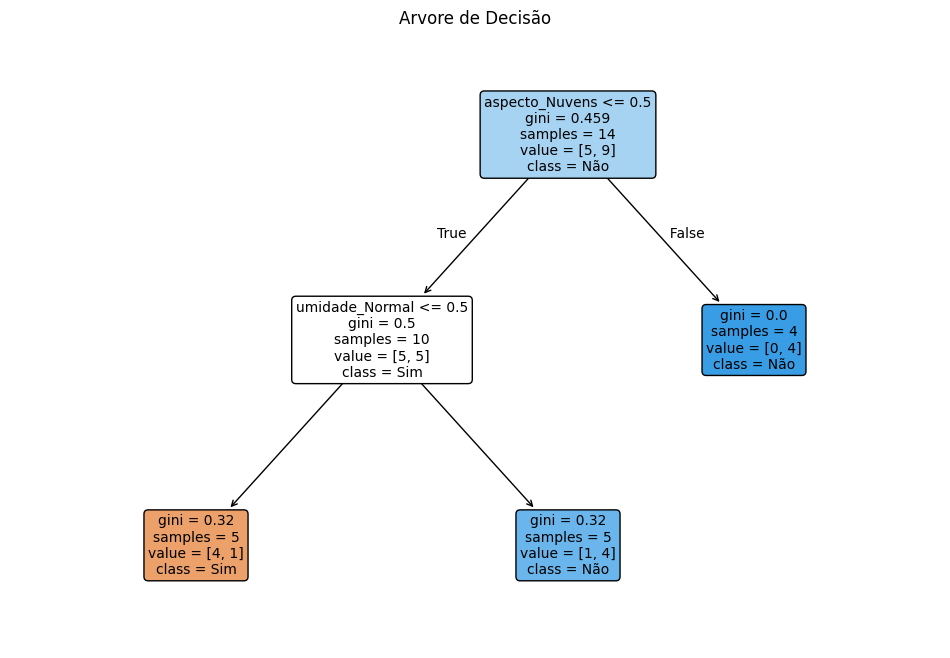

In [24]:
#Vizualização:

plt.figure(figsize=[12,8])
plot_tree(model,
          feature_names=X_encoded.columns,
          class_names=["Sim", "Não"],
          filled=True,
          rounded=True,
          fontsize=10)
plt.title('Arvore de Decisão')
plt.show()

In [27]:
# Previsões

def previsao(dados):
  df = pd.DataFrame([dados])
  df_teste = pd.get_dummies(df)
  df_teste = df_teste.reindex(columns=X_encoded.columns, fill_value=0)

  previsao = model.predict(df_teste)

  print(f"Dados: {dados}")
  print(f"Previsão: Jogar Tênis? --> {previsao[0]}")

prev = {'asp':"", "temp":"", "um":"", "vento":""}
prev['asp'] = input("Qual é o aspecto do dia? ")
prev['temp'] = input("Qual é a temperatura do dia? ")
prev['um'] = input("Qual é a umidade do dia? ")
prev['vento'] = input("Como está o vendo do dia de hoje? ")

previsao(prev)

Qual é o aspecto do dia? Nuvens
Qual é a temperatura do dia? Ameno
Qual é a umidade do dia? Normal
Como está o vendo do dia de hoje? Forte
Dados: {'asp': 'Nuvens', 'temp': 'Ameno', 'um': 'Normal', 'vento': 'Forte'}
Previsão: Jogar Tênis? --> Não
